# Single layer models

The objective of this lab is to implement a single-layer network model that consists solely of an affine transformation of the inputs. The relevant material is covered in slides 12-23 of the first lecture.

We will first implement the forward propagation of inputs to the network to produce predicted outputs. We will then move on to considering how to use gradients of an error function evaluated on the outputs to compute the gradients with respect to the model parameters, allowing us to perform an iterative gradient-descent training procedure. In the final exercise, you will use an interactive visualization to explore the role of different hyperparameters in gradient-descent based training methods.

#### A note on random number generators

It is generally good practice (for machine learning applications **not** for cryptography!) to seed a pseudo-random number generator once at the beginning of each experiment. This makes it easier to reproduce results, as the same random draws will be produced each time the experiment is run (e.g., the same random initializations used for parameters). Therefore, whenever we need to generate random values during this course, we will create a seeded random number generator object as we do in the cell below.

In [1]:
import numpy as np
seed = 27092016 
rng = np.random.RandomState(seed)

## Exercise 1: Linear and affine transforms

Any *linear transform* (also called a linear map) on a finite-dimensional vector space can be parametrized by a matrix. For example, if we consider $\boldsymbol{x} \in \mathbb{R}^{D}$ as the input space of a model with $D$ dimensional real-valued inputs, then a matrix $\mathbf{W} \in \mathbb{R}^{K\times D}$ can be used to define a prediction model consisting solely of a linear transform of the inputs:

\begin{equation}
    \boldsymbol{y} = \mathbf{W} \boldsymbol{x}
    \qquad
    \Leftrightarrow
    \qquad
    y_k = \sum_{d=1}^D \left( W_{kd} x_d \right) \quad \forall k \in \left\lbrace 1 \dots K\right\rbrace
\end{equation}

with $\boldsymbol{y} \in \mathbb{R}^K$ the $K$-dimensional real-valued output of the model. Geometrically, we can think of a linear transform as some combination of rotation, scaling, reflection, and shearing of the input.

An *affine transform* consists of a linear transform plus an additional translation on the output space parametrized by a vector $\boldsymbol{b} \in \mathbb{R}^K$. A model consisting of an affine transformation of the inputs can then be defined as:

\begin{equation}
    \boldsymbol{y} = \mathbf{W}\boldsymbol{x} + \boldsymbol{b}
    \qquad
    \Leftrightarrow
    \qquad
    y_k = \sum_{d=1}^D \left( W_{kd} x_d \right) + b_k \quad \forall k \in \left\lbrace 1 \dots K\right\rbrace
\end{equation}

In machine learning, we usually refer to the matrix $\mathbf{W}$ as a *weight matrix* and the vector $\boldsymbol{b}$ as a *bias vector*.

Generally, rather than working with a single data vector $\boldsymbol{x}$, we will work with batches of datapoints $\left\lbrace \boldsymbol{x}^{(b)}\right\rbrace_{b=1}^B$. We could calculate the outputs for each input in the batch sequentially:

\begin{align}
    \boldsymbol{y}^{(1)} &= \mathbf{W}\boldsymbol{x}^{(1)} + \boldsymbol{b}\\
    \boldsymbol{y}^{(2)} &= \mathbf{W}\boldsymbol{x}^{(2)} + \boldsymbol{b}\\
    \dots &\\
    \boldsymbol{y}^{(B)} &= \mathbf{W}\boldsymbol{x}^{(B)} + \boldsymbol{b}\\
\end{align}

by looping over each input in the batch and calculating the output. However, loops in Python are slow (particularly compared to compiled and typed languages such as C). This is due, at least in part, to the large overhead in dynamically inferring variable types. Consequently, we want to avoid having loops where this overhead would be the dominant computational cost.

For array-based numerical operations, one way of overcoming this bottleneck is to *vectorize* operations, that is, computing all of them at once. NumPy `ndarrays` are typed arrays for which operations like basic element-wise arithmetic and linear algebra operations (*e.g.*, computing matrix-matrix or matrix-vector products) are implemented by calls to highly-optimized compiled libraries. Therefore, implementing code directly using NumPy operations on arrays rather than by looping over array elements usually leads to very substantial performance gains.

As a simple example, we can consider adding up two arrays `a` and `b` and writing the result to a third array `c`. Let us start by initializing `a` and `b` with arbitrary values by running the cell below.

In [2]:
size = 1000
a = np.random.randn(size)
b = np.random.randn(size)

Now, we are going to measure how long it takes to add up each pair of values in the two arrays and write the results to a third array using a loop-based implementation. We will use the `%%timeit` magic briefly mentioned in the previous lab notebook, specifying the number of times to loop the code as 100 and repeating it 3 times for better consistency. Run the cell below to get a printout of the average time taken.

In [3]:
%%timeit -n 100 -r 3
c = np.empty(size)
for i in range(size):
    c[i] = a[i] + b[i]

327 μs ± 5.39 μs per loop (mean ± std. dev. of 3 runs, 100 loops each)


Now we will perform the corresponding summation with the overloaded addition operator of NumPy arrays. Again, run the cell below to get a printout of the average time taken.

In [4]:
%%timeit -n 100 -r 3
c = a + b

The slowest run took 8.19 times longer than the fastest. This could mean that an intermediate result is being cached.
3.01 μs ± 3 μs per loop (mean ± std. dev. of 3 runs, 100 loops each)


The first loop-based implementation should have taken on the order of milliseconds ($10^{-3}$ s) while the vectorized implementation should have taken on the order of microseconds ($10^{-6}$ s), i.e., a $\sim1000\times$ speedup. Hopefully this simple example should make it clear why we want to vectorize operations whenever possible!

Getting back to our affine model, ideally rather than individually computing the output corresponding to each input we should compute the outputs for all inputs in a batch using a vectorized implementation. As you saw last week, data providers return batches of inputs as arrays of shape `(batch_size, input_dim)`. In the mathematical notation used earlier, we can consider the input as a matrix $\mathbf{X}$ of dimensionality $B \times D$:

\begin{equation}
    \mathbf{X} = \left[ \boldsymbol{x}^{(1)} ~ \boldsymbol{x}^{(2)} ~ \dots ~ \boldsymbol{x}^{(B)} \right]^\mathrm{T}
\end{equation}

i.e., the $b^{\textrm{th}}$ input vector $\boldsymbol{x}^{(b)}$ corresponds to the $b^{\textrm{th}}$ row of $\mathbf{X}$. Similarly, we can define the $B \times K$ matrix of outputs $\mathbf{Y}$ as:

\begin{equation}
    \mathbf{Y} = \left[ \boldsymbol{y}^{(1)} ~ \boldsymbol{y}^{(2)} ~ \dots ~ \boldsymbol{y}^{(B)} \right]^\mathrm{T}
\end{equation}

We can then express the relationship between $\mathbf{X}$ and $\mathbf{Y}$ using [matrix multiplication](https://en.wikipedia.org/wiki/Matrix_multiplication) and addition as:

\begin{equation}
    \mathbf{Y} = \mathbf{X} \mathbf{W}^\mathrm{T} + \mathbf{B}
\end{equation}

where $\mathbf{B} = \left[ \boldsymbol{b} ~ \boldsymbol{b} ~ \dots ~ \boldsymbol{b} \right]^\mathrm{T}$ i.e., a $B \times K$ matrix with each row corresponding to the same bias vector. The weight matrix needs to be transposed here as the inner dimensions of a matrix multiplication must match i.e., for $\mathbf{C} = \mathbf{A} \mathbf{B}$ then if $\mathbf{A}$ is of dimensionality $K \times L$ and $\mathbf{B}$ is of dimensionality $M \times N$ then it must be the case that $L = M$ and $\mathbf{C}$ will be of dimensionality $K \times N$.

**Your Tasks:**

The first exercise for this lab is to implement *forward propagation* for a single-layer model consisting of an affine transformation of the inputs in the `fprop` function given as skeleton code in the cell below. This should work for a batch of inputs of shape `(batch_size, input_dim)` producing a batch of outputs of shape `(batch_size, output_dim)`.
  
You will probably want to use the NumPy `dot` function and [broadcasting features](http://docs.scipy.org/doc/numpy/user/basics.broadcasting.html) to implement this efficiently. If you are not familiar with either of these, you may wish to read the [hints](#Hints:-Using-the-dot-function-and-broadcasting) section below which provides some tips before attempting the exercise.

In [5]:
def fprop(inputs, weights, biases):
    """Forward propagates activations through the layer transformation.

    For inputs `x`, outputs `y`, weights `W` and biases `b` the layer
    corresponds to `y = W x + b`.

    Args:
        inputs: Array of layer inputs of shape (batch_size, input_dim).
        weights: Array of weight parameters of shape 
            (output_dim, input_dim).
        biases: Array of bias parameters of shape (output_dim, ).

    Returns:
        outputs: Array of layer outputs of shape (batch_size, output_dim).
    """
    return inputs.dot(weights.T) + biases

Once you have implemented `fprop` in the cell above you can test your implementation by running the cell below.

In [6]:
inputs = np.array([[0., -1., 2.], [-6., 3., 1.]])
weights = np.array([[2., -3., -1.], [-5., 7., 2.]])
biases = np.array([5., -3.])
true_outputs = np.array([[6., -6.], [-17., 50.]])

if not np.allclose(fprop(inputs, weights, biases), true_outputs):
    print('Wrong outputs computed.')
else:
    print('All outputs correct!')

All outputs correct!


### Hints: Using the `dot` function and broadcasting

For those new to NumPy below are some details on the `dot` function and broadcasting feature of NumPy that you may want to use for implementing the first exercise. If you are already familiar with these and have already completed the first exercise you can move on straight to [second exercise](#Exercise-2:-visualising-random-models).

#### `numpy.dot` function

Matrix-matrix, matrix-vector and vector-vector (dot) products can all be computed in NumPy using the [`dot`](http://docs.scipy.org/doc/numpy/reference/generated/numpy.dot.html) operator which generalizes all of these operation. For example if `A` and `B` are both two dimensional arrays, then `C = np.dot(A, B)` or equivalently `C = A.dot(B)` will compute the matrix product of `A` and `B` assuming `A` and `B` have compatible dimensions. Similarly if `a` and `b` are one dimensional arrays then `c = np.dot(a, b)` (which is equivalent to `c = a.dot(b)`) will compute the [scalar / dot product](https://en.wikipedia.org/wiki/Dot_product) of the two arrays. If `A` is a two-dimensional array and `b` a one-dimensional array `np.dot(A, b)` (which is equivalent to `A.dot(b)`) will compute the matrix-vector product of `A` and `b`. Examples of all three of these product types are shown in the cell below:

In [7]:
# Initialize arrays with arbitrary values
A = np.arange(9).reshape((3, 3))
B = np.ones((3, 3)) * 2
a = np.array([-1., 0., 1.])
b = np.array([0.1, 0.2, 0.3])
print(A.dot(B))  # Matrix-matrix product
print(B.dot(A))  # Reversed product of above. A.dot(B) != B.dot(A) in general
print(A.dot(b))  # Matrix-vector product
print(b.dot(A))  # Again A.dot(b) != b.dot(A) unless A is symmetric i.e. A == A.T
print(a.dot(b))  # Vector-vector scalar product

[[ 6.  6.  6.]
 [24. 24. 24.]
 [42. 42. 42.]]
[[18. 24. 30.]
 [18. 24. 30.]
 [18. 24. 30.]]
[0.8 2.6 4.4]
[2.4 3.  3.6]
0.19999999999999998


#### Broadcasting

Another NumPy feature it will be helpful to get familiar with is [broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html). Broadcasting allows you to apply operations to arrays of different shapes by letting numpy infer the missing parts, for example to add a one-dimensional array to a two-dimensional array or multiply a multidimensional array by a scalar. 

Keep in mind that the shapes must be compatible with one another, and that it may lead to erroneous results if the shapes are not as intended, so you are advised to make sure your arrays have the proper shapes.
The cell below gives a few examples:

In [8]:
# Initialize arrays with arbitrary values
A = np.arange(6).reshape((3, 2))
b = np.array([0.1, 0.2])
c = np.array([-1., 0., 1.])
print(A + b)  # Add b element-wise to all rows of A
print((A.T + c).T)  # Add c element-wise to all columns of A
print(A * b)  # Multiply each row of A element-wise by b

[[0.1 1.2]
 [2.1 3.2]
 [4.1 5.2]]
[[-1.  0.]
 [ 2.  3.]
 [ 5.  6.]]
[[0.  0.2]
 [0.2 0.6]
 [0.4 1. ]]


## Exercise 2: Visualizing random models

In this exercise you will use your `fprop` implementation to visualize the outputs of a single-layer affine transform model with two-dimensional inputs and a one-dimensional output. In this simple case, we can visualize the joint input-output space on a 3D axis.

For this task and the learning experiments later in the notebook we will use a regression dataset from the UCI machine learning repository. In particular we will use a version of the [Combined Cycle Power Plant dataset](http://archive.ics.uci.edu/ml/datasets/Combined+Cycle+Power+Plant), where the task is to predict the energy output of a power plant given observations of the local ambient conditions (e.g., temperature, pressure and humidity).

The original dataset has four input dimensions and a single target output dimension. We have preprocessed the dataset by [whitening](https://en.wikipedia.org/wiki/Whitening_transformation) it. Geometrically, this process rotates the data so that its [principal components](https://en.wikipedia.org/wiki/Principal_component_analysis) are aligned with the basis vectors, and then scales the data so that variance along each dimension is one (see [here](https://www.quora.com/What-is-the-use-of-Whitening-images-as-a-preprocessing-step-for-a-Convolutional-Neural-Network)).

If the original dataset has a covariance $\mathbf{C}$, a whitening transformation $\mathbf{D}$ is one which satisfies:
\begin{equation}
    \mathbf{D}^{\mathrm{T}} \mathbf{C} \mathbf{D} = \mathbf{I},
\end{equation}
where $\mathbf{I}$ is the identity matrix.

This can be considered a change of basis, where newly formed input features are decorrelated and have equivalent scale, which can lead to reduced learning times (see [here](https://proceedings.neurips.cc/paper/1990/file/758874998f5bd0c393da094e1967a72b-Paper.pdf)). We will only use the first two dimensions of the whitened inputs (corresponding to the first two principal components of the original inputs) so we can easily visualize the joint input-output space.

The dataset has been wrapped in the `CCPPDataProvider` class in the `mlp.data_providers` module and the data included as a compressed file in the data directory as `ccpp_data.npz`. Running the cell below will initialize an instance of this class, get a single batch of inputs and targets, and import the necessary `matplotlib` objects.

In [9]:
import matplotlib.pyplot as plt
# import sys
# sys.path.append('/path/to/mlpractical')
from mpl_toolkits.mplot3d import Axes3D
from mlp.data_providers import CCPPDataProvider

data_provider = CCPPDataProvider(
    which_set='train',
    input_dims=[0, 1],
    batch_size=5000, 
    max_num_batches=1, 
    shuffle_order=False
)

input_dim, output_dim = 2, 1

inputs, targets = data_provider.next()

Now run the cell below to plot the predicted outputs of a randomly initialized model across the two dimensional input space as well as the true target outputs. This sort of visualization can be a useful method (in low dimensions) to assess how well the model is likely to be able to fit the data and to judge appropriate initialization scales for the parameters. Each time you re-run the cell a new set of random parameters will be sampled.

**Your Tasks:**

Here you don't need to implement anything. Just run the cell several times and try to answer the following questions:

  * How do the weights and bias initialization scale affect the sort of predicted input-output relationships?
  * Do you think a linear model is a good choice for this data?

1. How do the weights and bias initialization scale affect the sort of predicted input-output relationships?
Weight affect how steep or flat input - output relationship is. Large weight will cause output to be more sensitive on any input changes.
On the other hand, small weight means that output less sensitive to input changes, often causing nearly flat relationship, meaning that each output is more likely to be the same/nearly the same with different input.
Bias initialization scale will shifted the predicted input-output graph away by adding offsets. In case of linear model, it usually means that the output will either be shifted upward or downward according to the value.
2. Do you think a linear model is a good choice for this data?
In our opinion, linear model can be used to predict data's output as they more or less resemble planar plane with no curvature in it. However it need some adjustment on bias and weight value to increase prediction's accuracy.


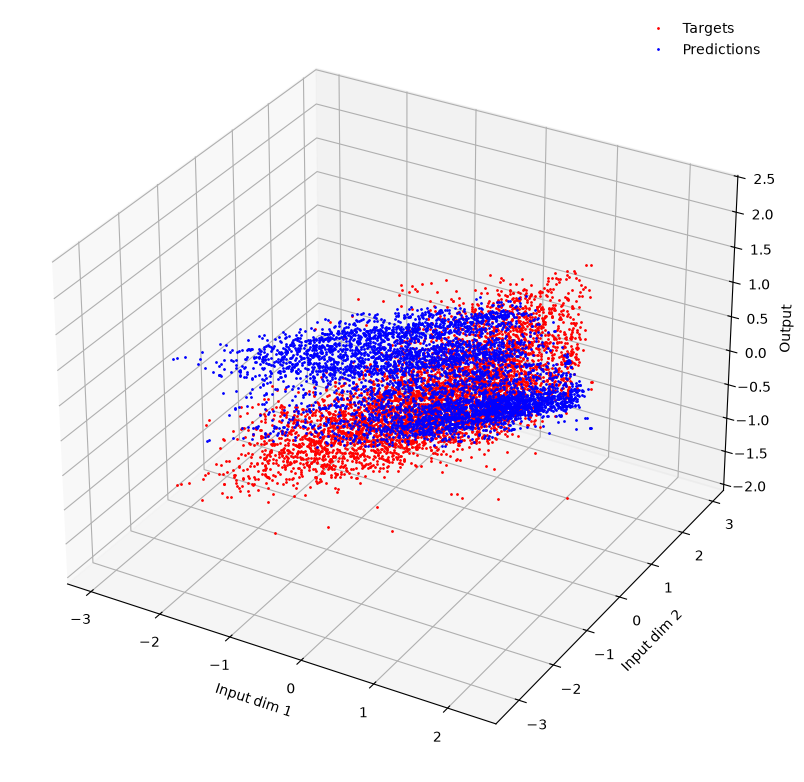

In [10]:
weights_init_range = 0.1
biases_init_range = 0.4

# Randomly initialise weights matrix
weights = rng.uniform(
    low=-weights_init_range, 
    high=weights_init_range, 
    size=(output_dim, input_dim)
)

#  Randomly initialise biases vector
biases = rng.uniform(
    low=-biases_init_range, 
    high=biases_init_range, 
    size=output_dim
)
# Calculate predicted model outputs
outputs = fprop(inputs, weights, biases)

# Plot target and predicted outputs against inputs on same axis
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(inputs[:, 0], inputs[:, 1], targets[:, 0], 'r.', ms=2)
ax.plot(inputs[:, 0], inputs[:, 1], outputs[:, 0], 'b.', ms=2)
ax.set_xlabel('Input dim 1')
ax.set_ylabel('Input dim 2')
ax.set_zlabel('Output')
ax.legend(['Targets', 'Predictions'], frameon=False)
fig.tight_layout()
plt.show()

## Exercise 3: Computing the error function and its gradient

We will now consider the task of regression as covered in the first lecture. Given a set of inputs $\left\lbrace \boldsymbol{x}^{(n)}\right\rbrace_{n=1}^N$, the aim in a regression problem is to produce outputs $\left\lbrace \boldsymbol{y}^{(n)}\right\rbrace_{n=1}^N$ that are as 'close' as possible to a set of targets $\left\lbrace \boldsymbol{t}^{(n)}\right\rbrace_{n=1}^N$. The measure of 'closeness' or distance between target and predicted outputs can vary and is usually a design choice.

A very common choice is the squared Euclidean distance between the predicted and target outputs. This can be computed as the sum of the squared differences between each element in the target and predicted outputs. A widespread convention is to multiply this value by $\frac{1}{2}$ as this gives a slightly nicer expression for the error gradient. The error for the $n^{\textrm{th}}$ training example is then expressed by:

\begin{equation}
    E^{(n)} = \frac{1}{2} \sum_{k=1}^K \left\lbrace \left( y^{(n)}_k - t^{(n)}_k \right)^2 \right\rbrace.
\end{equation}

The overall error is defined as the *average* of this value across all training examples:

\begin{equation}
    \bar{E} = \frac{1}{N} \sum_{n=1}^N \left\lbrace E^{(n)} \right\rbrace.
\end{equation}

*Note: Here we are using a slightly different convention from the lectures. There the overall error was considered to be the sum of the individual error terms rather than the mean. To differentiate between the two we will use $\bar{E}$ to represent the average error here as opposed to sum of errors $E$ as used in the slides with $\bar{E} = \frac{E}{N}$. Normalizing by the number of training examples is helpful to do in practice as this means we can more easily compare errors across datasets/batches of different sizes, and more importantly it means the size of our gradient updates will be independent of the number of training examples summed over.*

Solving the regression problem means finding parameters of the model which minimize $\bar{E}$. For our simple single-layer affine model here, that corresponds to finding weights $\mathbf{W}$ and biases $\boldsymbol{b}$ which minimize $\bar{E}$.

As mentioned in the lecture, in this case there is actually a closed form solution for the optimal weights and bias parameters. This is the linear least-squares solution those doing MLPR will have come across.

However, in general we will be interested in models where closed form solutions do not exist. Therefore, we will generally use iterative gradient descent based optimization methods to find parameters which (locally) minimize the error function. A basic requirement of being able to do gradient-descent based training is (unsurprisingly) the ability to evaluate gradients of the error function.

Our end goal is to calculate gradients of the error function with respect to the model parameters $\mathbf{W}$ and $\boldsymbol{b}$. As a first step here we will consider the gradient of the error function with respect to the model outputs $\left\lbrace \boldsymbol{y}^{(n)}\right\rbrace_{n=1}^N$. This can be written:

\begin{equation}
    \frac{\partial \bar{E}}{\partial \boldsymbol{y}^{(n)}} = \frac{1}{N} \left( \boldsymbol{y}^{(n)} - \boldsymbol{t}^{(n)} \right)
    \qquad \Leftrightarrow \qquad
    \frac{\partial \bar{E}}{\partial y^{(n)}_k} = \frac{1}{N} \left( y^{(n)}_k - t^{(n)}_k \right) \quad \forall k \in \left\lbrace 1 \dots K\right\rbrace
\end{equation}

*i.e.*, the gradient of the error function with respect to the $n^{\textrm{th}}$ model output is the difference between the $n^{\textrm{th}}$ model and target outputs, corresponding to the $\boldsymbol{\delta}^{(n)}$ terms mentioned in the lecture slides.

**Your Tasks:**

Using the equations given above, implement functions computing the mean sum of squared differences error and its gradient with respect to the model outputs. You should implement the functions using the provided skeleton definitions in the cell below.

In [11]:
def error(outputs, targets):
    """Calculates error function given a batch of outputs and targets.

    Args:
        outputs: Array of model outputs of shape (batch_size, output_dim).
        targets: Array of target outputs of shape (batch_size, output_dim).

    Returns:
        Scalar error function value.
    """
    return np.sum(((outputs - targets) ** 2) / 2)/outputs.shape[0]
    
def error_grad(outputs, targets):
    """Calculates gradient of error function with respect to model outputs.

    Args:
        outputs: Array of model outputs of shape (batch_size, output_dim).
        targets: Array of target outputs of shape (batch_size, output_dim).

    Returns:
        Gradient of error function with respect to outputs.
        This will be an array of shape (batch_size, output_dim).
    """
    return (outputs - targets) / outputs.shape[0]

Check your implementation by running the test cell below.

In [12]:
outputs = np.array([[1., 2.], [-1., 0.], [6., -5.], [-1., 1.]])
targets = np.array([[0., 1.], [3., -2.], [7., -3.], [1., -2.]])
true_error = 5.
true_error_grad = np.array([[0.25, 0.25], [-1., 0.5], [-0.25, -0.5], [-0.5, 0.75]])

if not error(outputs, targets) == true_error:
    print('Error calculated incorrectly.')
elif not np.allclose(error_grad(outputs, targets), true_error_grad):
    print('Error gradient calculated incorrectly.')
else:
    print('Error function and gradient computed correctly!')

Error function and gradient computed correctly!


## Exercise 4: Computing gradients with respect to the parameters

In the previous exercise you implemented a function computing the gradient of the error function with respect to the model outputs. For gradient-descent based training, we need to be able to evaluate the gradient of the error function with respect to the model parameters.

Using the [chain rule for derivatives](https://en.wikipedia.org/wiki/Chain_rule#Higher_dimensions), we can write the partial derivative of the error function with respect to single elements of the weight matrix and bias vector as:

\begin{equation}
    \frac{\partial E}{\partial W_{kj}} = \sum_{n=1}^N \left\lbrace \frac{\partial E}{\partial y^{(n)}_k} \frac{\partial y^{(n)}_k}{\partial W_{kj}} \right\rbrace
    \quad \textrm{and} \quad
    \frac{\partial E}{\partial b_k} = \sum_{n=1}^N \left\lbrace \frac{\partial E}{\partial y^{(n)}_k} \frac{\partial y^{(n)}_k}{\partial b_k} \right\rbrace.
\end{equation}

From the definition of our model at the beginning we have:

\begin{equation}
    y^{(n)}_k = \sum_{d=1}^D \left\lbrace W_{kd} x^{(n)}_d \right\rbrace + b_k
    \quad \Rightarrow \quad
    \frac{\partial y^{(n)}_k}{\partial W_{kj}} = x^{(n)}_j
    \quad \textrm{and} \quad
    \frac{\partial y^{(n)}_k}{\partial b_k} = 1.
\end{equation}

Putting this together we get that:

\begin{equation}
    \frac{\partial E}{\partial W_{kj}} = 
    \sum_{n=1}^N \left\lbrace \frac{\partial E}{\partial y^{(n)}_k} x^{(n)}_j \right\rbrace
    \quad \textrm{and} \quad
    \frac{\partial E}{\partial b_{k}} = 
    \sum_{n=1}^N \left\lbrace \frac{\partial E}{\partial y^{(n)}_k} \right\rbrace.
\end{equation}

Although this may seem a bit of a roundabout way to get to these results, this method of decomposing the error gradient with respect to the parameters in terms of the gradient of the error function with respect to the model outputs and the derivatives of the model outputs with respect to the model parameters is the key element that allows calculating the parameter gradients of more complex models we will study later in the course.

**Your Tasks:**

Implement a function calculating the gradient of the error function with respect to the weight and bias parameters of the model given the already computed gradient of the error function with respect to the model outputs. You should implement this in the `grads_wrt_params` function in the cell below.

In [13]:
def grads_wrt_params(inputs, grads_wrt_outputs):
    """Calculates gradients with respect to model parameters.

    Args:
        inputs: array of inputs to model of shape (batch_size, input_dim)
        grads_wrt_to_outputs: array of gradients of with respect to the model
            outputs of shape (batch_size, output_dim).

    Returns:
        list of arrays of gradients with respect to the model parameters
        `[grads_wrt_weights, grads_wrt_biases]`.
    """
    return [grads_wrt_outputs.T.dot(inputs), np.sum(grads_wrt_outputs, axis=0)]

Check your implementation by running the test cell below.

In [14]:
inputs = np.array([[1., 2., 3.], [-1., 4., -9.]])
grads_wrt_outputs = np.array([[-1., 1.], [2., -3.]])
true_grads_wrt_weights = np.array([[-3., 6., -21.], [4., -10., 30.]])
true_grads_wrt_biases = np.array([1., -2.])

grads_wrt_weights, grads_wrt_biases = grads_wrt_params(
    inputs, grads_wrt_outputs)

if not np.allclose(true_grads_wrt_weights, grads_wrt_weights):
    print('Gradients with respect to weights incorrect.')
elif not np.allclose(true_grads_wrt_biases, grads_wrt_biases):
    print('Gradients with respect to biases incorrect.')
else:
    print('All parameter gradients calculated correctly!')

All parameter gradients calculated correctly!


## Exercise 5: wrapping the functions into reusable components

In exercises 1, 3 and 4 you implemented methods to compute the predicted outputs of our model, evaluate the error function and its gradient on the outputs and finally to calculate the gradients of the error with respect to the model parameters. Together they constitute all the basic ingredients we need to implement a gradient-descent based iterative learning procedure.

Although you could implement training code which directly uses the functions you defined, this would only be usable for this particular model architecture. In subsequent labs we will want to use the affine transform functions as the basis for more interesting multi-layer models. We will therefore wrap the implementations you just wrote in to reusable components that we can combine to build more complex models later in the course.

**Your Tasks:**

  * In the [`mlp.layers`](../mlp/layers.py) module, use your implementations of `fprop` and `grad_wrt_params` above to implement the corresponding methods in the skeleton `AffineLayer` class provided.
  * In the [`mlp.errors`](../mlp/errors.py) module use your implementation of `error` and `error_grad` to implement the `__call__` and `grad` methods respectively of the skeleton `SumOfSquaredDiffsError` class provided. Note `__call__` is a special Python method that allows an object to be used with a function call syntax.

Run the cell below to use your completed `AffineLayer` and `SumOfSquaredDiffsError` implementations to train a single-layer model using batch gradient descent on the CCPP dataset. Remember to reload the notebook if you made changes to the `mlp` module.

Epoch 1: 0.0s to complete
    error(train)=1.67e-01
Epoch 2: 0.0s to complete
    error(train)=9.30e-02
Epoch 3: 0.0s to complete
    error(train)=7.95e-02
Epoch 4: 0.0s to complete
    error(train)=7.71e-02
Epoch 5: 0.0s to complete
    error(train)=7.66e-02
Epoch 6: 0.0s to complete
    error(train)=7.65e-02
Epoch 7: 0.0s to complete
    error(train)=7.65e-02
Epoch 8: 0.0s to complete
    error(train)=7.65e-02
Epoch 9: 0.0s to complete
    error(train)=7.63e-02
Epoch 10: 0.0s to complete
    error(train)=7.64e-02


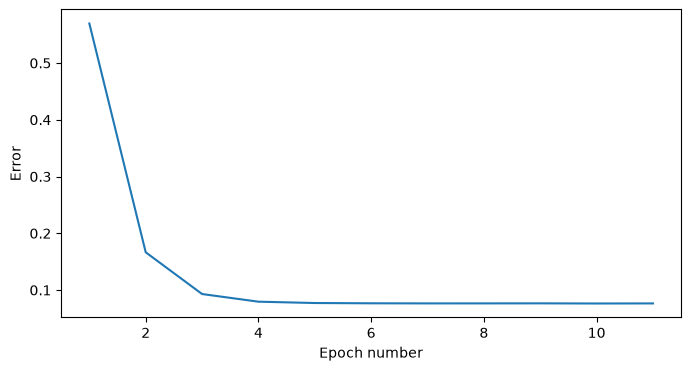

In [15]:
from mlp.layers import AffineLayer
from mlp.errors import SumOfSquaredDiffsError
from mlp.models import SingleLayerModel
from mlp.initialisers import UniformInit, ConstantInit
from mlp.learning_rules import GradientDescentLearningRule
from mlp.optimisers import Optimiser
import logging

# Seed a random number generator
seed = 27092016 
rng = np.random.RandomState(seed)

# Set up a logger object to print info about the training run to stdout
logger = logging.getLogger()
logger.setLevel(logging.INFO)
logger.handlers = [logging.StreamHandler()]

# Create data provider objects for the CCPP training set
train_data = CCPPDataProvider('train', [0, 1], batch_size=100, rng=rng)
input_dim, output_dim = 2, 1

# Create a parameter initialiser which will sample random uniform values
# from [-0.1, 0.1]
param_init = UniformInit(-0.1, 0.1, rng=rng)

# Create our single layer model
layer = AffineLayer(input_dim, output_dim, param_init, param_init)
model = SingleLayerModel(layer)

# Initialise the error object
error = SumOfSquaredDiffsError()

# Use a basic gradient descent learning rule with a small learning rate
learning_rule = GradientDescentLearningRule(learning_rate=1e-2)

# Use the created objects to initialise a new Optimiser instance.
optimiser = Optimiser(model, error, learning_rule, train_data)

# Run the optimiser for 5 epochs (full passes through the training set)
# printing statistics every epoch.
stats, keys, _ = optimiser.train(num_epochs=10, stats_interval=1)

# Plot the change in the error over training.
fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111)
ax.plot(np.arange(1, stats.shape[0] + 1), stats[:, keys['error(train)']])
ax.set_xlabel('Epoch number')
ax.set_ylabel('Error')
plt.show()

Using similar code to exercise 2, we can visualise the joint input-output space for the trained model. If you implemented the required methods correctly you should now see a much improved fit between predicted and target outputs when running the cell below.

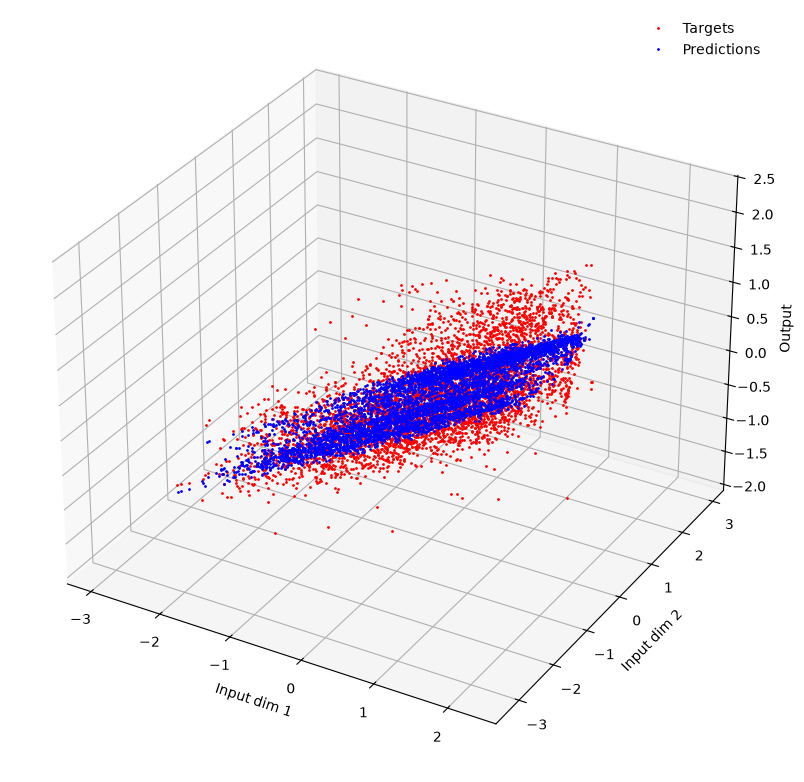

In [16]:
data_provider = CCPPDataProvider(
    which_set='train',
    input_dims=[0, 1],
    batch_size=5000, 
    max_num_batches=1, 
    shuffle_order=False
)

inputs, targets = data_provider.next()

# Calculate predicted model outputs
outputs = model.fprop(inputs)[-1]

# Plot target and predicted outputs against inputs on same axis
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(inputs[:, 0], inputs[:, 1], targets[:, 0], 'r.', ms=2)
ax.plot(inputs[:, 0], inputs[:, 1], outputs[:, 0], 'b.', ms=2)
ax.set_xlabel('Input dim 1')
ax.set_ylabel('Input dim 2')
ax.set_zlabel('Output')
ax.legend(['Targets', 'Predictions'], frameon=False)
fig.tight_layout()
plt.show()

## Exercise 6: Visualizing training trajectories in parameter space

Running the cell below will display an interactive widget which plots the trajectories of gradient-based training of the single-layer affine model on the CCPP dataset in the three dimensional parameter space (two weights plus bias) from random initializations. Also shown on the right is a plot of the evolution of the error function (evaluated on the current batch) over training. By moving the sliders you can alter the training hyperparameters to investigate the effect they have on how training proceeds. The hyperparameters are as follows:

- `n_epochs`: number of training epochs,
- `batch_size`: number of data points per batch,
- `log_lr`: logarithm of the learning rate,
- `n_inits`: number of different parameter initializations,
- `w_scale`: min/max initial weight value,
- `b_scale`: min/max initial bias value,
- `elev`/`azim`: spherical coordinates for camera position.

When adjusting these hyperparameters, keep in mind that the magnitude of each (per batch) update is independent of the batch size. Increasing the batch size may therefore necessitate a larger number of epochs to ensure convergence, or a larger learning rate.

**Your Tasks:**

No need to implement anything. Run the cell and explore the following questions:

  * Are there multiple local minima in parameter space here? Why?
  * What are the effects of using very small learning rates? And very large learning rates?
  * How does the batch size affect learning?
  
**Note:** You don't need to understand how the code below works. The idea of this exercise is to help you understand the role of the various hyperparameters involved in gradient-descent based training methods.

1. Are there multiple local minima in parameter space here? Why?
Increasing n_inits produces multiple parameter trajectories starting from different random initializations. As shown in the plot, these trajectories converge towards approximately the same region in parameter space (all line leading to 1 point), while their batch errors decrease towards similar values.
This behaviour is expected because the single-layer affine model with squared error has a convex quadratic loss function. Therefore, there are no suboptimal local minima, and every local minimum is also a global minimum. If the input data matrix has full column rank, the global minimum is unique.
2. What are the effects of using very small learning rates? And very large learning rates?
Very small learning rates result in small parameter updates, leading to slow convergence and requiring more training iterations. Larger learning rates can accelerate convergence, but excessively large values may cause the parameters to overshoot the minimum, oscillate, or diverge.
3. How does the batch size affect learning?
Smaller batch sizes produce noisier gradient estimates, resulting in more fluctuating parameter trajectories, due to frequent update in parameters per epoch, and batch errors. Larger batch sizes produce more stable gradient estimates but fewer updates per epoch. Consequently, larger batch sizes may require more training epochs to achieve convergence (larger n_epochs will mitigate the effect).

In [17]:
from ipywidgets import interact
%matplotlib inline

def setup_figure():
    # create figure and axes
    fig = plt.figure(figsize=(12, 6))
    ax1 = fig.add_axes([0., 0., 0.5, 1.], projection='3d')
    ax2 = fig.add_axes([0.6, 0.1, 0.4, 0.8])
    # set axes properties
    ax2.spines['right'].set_visible(False)
    ax2.spines['top'].set_visible(False)
    ax2.yaxis.set_ticks_position('left')
    ax2.xaxis.set_ticks_position('bottom')
    #ax2.set_yscale('log')
    ax1.set_xlim((-2, 2))
    ax1.set_ylim((-2, 2))
    ax1.set_zlim((-2, 2))
    #set axes labels and title
    ax1.set_title('Parameter trajectories over training')
    ax1.set_xlabel('Weight 1')
    ax1.set_ylabel('Weight 2')
    ax1.set_zlabel('Bias')
    ax2.set_title('Batch errors over training')
    ax2.set_xlabel('Batch update number')
    ax2.set_ylabel('Batch error')
    return fig, ax1, ax2

def visualise_training(n_epochs=1, batch_size=200, log_lr=-1., n_inits=1,
                       w_scale=1., b_scale=1., elev=30., azim=0.):
    fig, ax1, ax2 = setup_figure()
    # create seeded random number generator
    rng = np.random.RandomState(1234)
    # create data provider
    data_provider = CCPPDataProvider(
        input_dims=[0, 1],
        batch_size=batch_size, 
        shuffle_order=False,
    )
    learning_rate = 10 ** log_lr
    n_batches = data_provider.num_batches
    weights_traj = np.empty((n_inits, n_epochs * n_batches + 1, 1, 2))
    biases_traj = np.empty((n_inits, n_epochs * n_batches + 1, 1))
    errors_traj = np.empty((n_inits, n_epochs * n_batches))
    # randomly initialise parameters
    weights = rng.uniform(-w_scale, w_scale, (n_inits, 1, 2))
    biases = rng.uniform(-b_scale, b_scale, (n_inits, 1))
    # store initial parameters
    weights_traj[:, 0] = weights
    biases_traj[:, 0] = biases
    # iterate across different initialisations
    for i in range(n_inits):
        # iterate across epochs
        for e in range(n_epochs):
            # iterate across batches
            for b, (inputs, targets) in enumerate(data_provider):
                outputs = fprop(inputs, weights[i], biases[i])
                errors_traj[i, e * n_batches + b] = error(outputs, targets)
                grad_wrt_outputs = error_grad(outputs, targets)
                weights_grad, biases_grad = grads_wrt_params(inputs, grad_wrt_outputs)
                weights[i] -= learning_rate * weights_grad
                biases[i] -= learning_rate * biases_grad
                weights_traj[i, e * n_batches + b + 1] = weights[i]
                biases_traj[i, e * n_batches + b + 1] = biases[i]
    # choose a different color for each trajectory
    colors = plt.cm.jet(np.linspace(0, 1, n_inits))
    # plot all trajectories
    for i in range(n_inits):
        lines_1 = ax1.plot(
            weights_traj[i, :, 0, 0], 
            weights_traj[i, :, 0, 1], 
            biases_traj[i, :, 0], 
            '-', c=colors[i], lw=2)
        lines_2 = ax2.plot(
            np.arange(n_batches * n_epochs),
            errors_traj[i],
            c=colors[i]
        )
    ax1.view_init(elev, azim)
    plt.show()

w = interact(
    visualise_training,
    elev=(-90, 90, 2),
    azim=(-180, 180, 2), 
    n_epochs=(1, 50), 
    batch_size=(10, 1000, 100),
    log_lr=(-5., 1.),
    w_scale=(0., 4.),
    b_scale=(0., 4.),
    n_inits=(1, 10)
)

for child in w.widget.children:
    child.layout.width = '100%'

interactive(children=(IntSlider(value=1, description='n_epochs', max=50, min=1), IntSlider(value=200, descript…

# Hints:
- Remember an affine single layer model is an linear with respect to it's parameters, such that any given output $y$ can be expressed as $y = w_1 x_1 + w_2 x_2 + b$. Subsituting this into the loss function we have: 
\begin{equation}
    E =  \sum_{n=1}^K \frac{1}{2}  \left( y^{(n)} - t^{(n)} \right)^2 = \sum_{n=1}^K \frac{1}{2}  \left( w_1 x_1^{(n)} + w_2 x_2^{(n)} + b - t^{(n)} \right)^2.
\end{equation}
The loss surface is therefore *quadratic* with respect to parameters $w_1, w_2, b$. What effect does this have on the number of minima? There is only one result as to get w + x = 0 in quadratic, there's only 1 w that satisfies the equation

- Note that by using batch-wise updates, we are computing gradients of loss surface described by a subset $B < N$ of the training data:
\begin{equation}
    E =  \sum_{n=1}^B \frac{1}{2}  \left( y^{(n)} - t^{(n)} \right)^2.
\end{equation}
Hence, this gradient direction is only an approximation of the optimal update direction dictated by the full dataset. With very small batch sizes, what convergence behaviour would we therefore expect? With very small batch sizes, we would expect noisier gradient estimates, since each update is based on only a small subset of the training data. As a result, the parameter trajectories may fluctuate or zigzag towards the minimum rather than following a smooth path. The batch error may also fluctuate significantly, and with a constant learning rate, the parameters may continue oscillating around the minimum instead of converging precisely to it.

# PyTorch

PyTorch is a deep-learning framework that allows us to easily build and train neural networks. It is based on the concept of [tensors](https://pytorch.org/docs/stable/tensors.html), which are multidimensional arrays. In this section, we will use PyTorch to build a simple neural network and train it on the Combined Cycle Power Plant dataset dataset.

In [18]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

To ensure [reproducibility](https://pytorch.org/docs/stable/notes/randomness.html), we will set the seed of the random number generator to a fixed value.

We will also use the same hyperparameters as in the previous section.

In [19]:
torch.manual_seed(seed)

learning_rate = 1e-2
num_epochs = 10
batch_size = 100
input_dim = 2
output_dim = 1

To work with data in PyTorch, we need to create a [Dataset](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) object. This object will be used by a [DataLoader](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) object to load the data in batches. The DataLoader object will also shuffle the data at each epoch.

*Here, we do not shuffle the data by setting `shuffle=False` as we want to compare the results with the previous section. However, it is strongly advised to shuffle the data in the training set, but not in the validation or the test set. Can you think about why?*

For a dataset to be used with PyTorch, it needs to have the following methods:
- `__len__`: returns the size of the dataset,
- `__getitem__`: returns the $i^{\textrm{th}}$ sample of the dataset.

Also, the data needs to be converted to PyTorch tensors. This can be done by using the [TensorDataset](https://pytorch.org/docs/stable/data.html#torch.utils.data.TensorDataset) class or the `torch.from_numpy()` method.

In [20]:
class CCPPDataProvider(Dataset):
    """Combined Cycle Power Plant dataset."""
    
    def __init__(self, data_path, which_set='train', x_dims=None):
        super().__init__()
        self.data = np.load(data_path)

        assert which_set in ['train', 'valid'], (
            'Expected which_set to be either train or valid '
            'Got {0}'.format(which_set)
        )
        self.x = self.data[which_set + '_inputs']
        if x_dims is not None:
            self.x = self.x[:, x_dims]
        self.x = torch.from_numpy(self.x).to(torch.float32)
        self.t = self.data[which_set + '_targets']
        self.t = torch.from_numpy(self.t).to(torch.float32)

    def __len__(self):
        return len(self.x)
    
    def __getitem__(self, idx):
        return self.x[idx], self.t[idx]

The `Linear` layer, also called a fully-connected layer, performs the affine operation described above by combining the input data with the weights and biases.

In [21]:
class SingleLayerModel(nn.Module):
    """Single layer model."""
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.layer = nn.Linear(input_dim, output_dim) 
        
    def forward(self, x):
        return self.layer(x)

The weights and biases for each layer (neural network parameters) are initialized randomly but we can decide what distribution to sample from using the [`torch.init.module`](https://pytorch.org/docs/stable/nn.init.html). Here, we will use a uniform distribution for the weights and set the biases to 0.

In [22]:
def weights_init(m):
    """Reinitialize model weights"""
    classname = m.__class__.__name__
    if classname.find('Linear') != -1:
        nn.init.uniform_(m.weight.data, -0.1, 0.1)
        nn.init.constant_(m.bias.data, 0)


In [23]:
default_data_dir = os.path.join(os.getcwd(), 'data')
if not os.path.isdir(default_data_dir):
    default_data_dir = os.path.join(os.getcwd(), os.pardir, 'data')
data_path = os.path.join(
    os.environ.get('MLP_DATA_DIR', default_data_dir), 'ccpp_data.npz')
assert os.path.isfile(data_path), ('Data file does not exist at expected path: ' + data_path)

dataset = CCPPDataProvider(data_path, which_set='train', x_dims=[0, 1])

dataloader = DataLoader(dataset, batch_size=100, shuffle=False)

The error between predictions and ground truth values is calculated using the mean square error loss function. This function is implemented in PyTorch as [`torch.nn.MSELoss`](https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html).

There are many [optimizers](https://pytorch.org/docs/stable/optim.html#module-torch.optim) available in PyTorch. Here, we will use the [Adam](https://pytorch.org/docs/stable/optim.html#torch.optim.Adam) optimizer. This optimizer takes as input the parameters to optimize and the learning rate.

In [24]:
model = SingleLayerModel(input_dim, output_dim)
model.apply(weights_init)

print(f"Model structure: {model}\n\n")

loss = nn.MSELoss()  # Mean Squared Error loss
optimizer = optim.Adam(model.parameters(), lr=learning_rate)  # Adam optimizer

Model structure: SingleLayerModel(
  (layer): Linear(in_features=2, out_features=1, bias=True)
)




The training loop will be similar to the one in the previous section. For every epoch, we will iterate through the dataset by batches. For each batch, we will compute the predictions, the loss, and the gradients. We will then update the parameters using the gradients and the optimizer.

However, we will use the [`torch.optim.zero_grad()`](https://pytorch.org/docs/stable/generated/torch.optim.Optimizer.zero_grad.html) method to set the gradients to zero before computing the gradients of the loss function with respect to the parameters. *Think about why we need to do this and what would happen if we do not?*

We will also use the [`torch.optim.step()`](https://pytorch.org/docs/stable/generated/torch.optim.Optimizer.step.html) method to update the parameters.

Epoch [1/10]	Error(train): 0.4644
Epoch [2/10]	Error(train): 0.1591
Epoch [3/10]	Error(train): 0.1532
Epoch [4/10]	Error(train): 0.1532
Epoch [5/10]	Error(train): 0.1533
Epoch [6/10]	Error(train): 0.1533
Epoch [7/10]	Error(train): 0.1533
Epoch [8/10]	Error(train): 0.1533
Epoch [9/10]	Error(train): 0.1533
Epoch [10/10]	Error(train): 0.1533


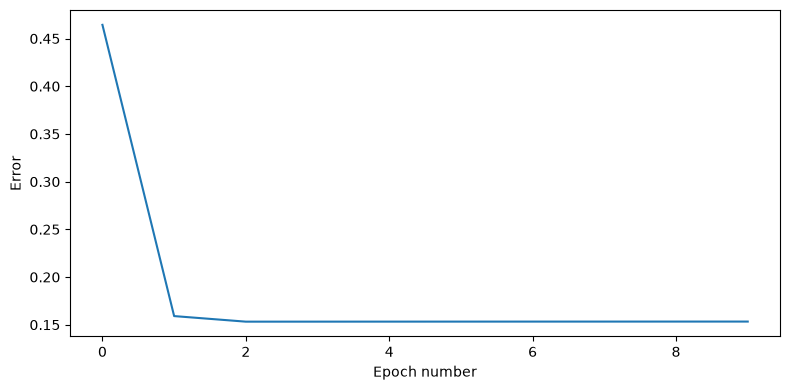

In [25]:
# Keep track of the loss values over training
train_loss = [] 

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0

    for x, t in dataloader:
        y = model(x)
        E_value = loss(y, t)
        optimizer.zero_grad()
        E_value.backward()
        optimizer.step()
        epoch_loss += E_value.item()
    # Calculate average loss for this epoch
    avg_epoch_loss = epoch_loss / len(dataloader)
    print(f"Epoch [{epoch+1}/{num_epochs}]\tError(train): {avg_epoch_loss:.4f}")
    train_loss.append(avg_epoch_loss)

# Plot the change in the error over training.
fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111)
ax.plot(train_loss)
ax.set_xlabel('Epoch number')
ax.set_ylabel('Error')
fig.tight_layout()
plt.show()

When the training is finished, we can compute the predictions and plot them along with the ground truth values.

Here, we will use the [`torch.no_grad()`](https://pytorch.org/docs/stable/generated/torch.no_grad.html) context manager to disable gradient calculation as we do not need it for the predictions.

In [26]:
predictions = []
inputs = []
targets = []

with torch.no_grad():
    model.eval()
    for x, t in dataloader:
        inputs.append(x.numpy())
        targets.append(t.numpy())
        y = model(x)
        predictions.append(y.numpy())
        
predictions = np.concatenate(predictions, axis=0)
inputs = np.concatenate(inputs, axis=0)
targets = np.concatenate(targets, axis=0)

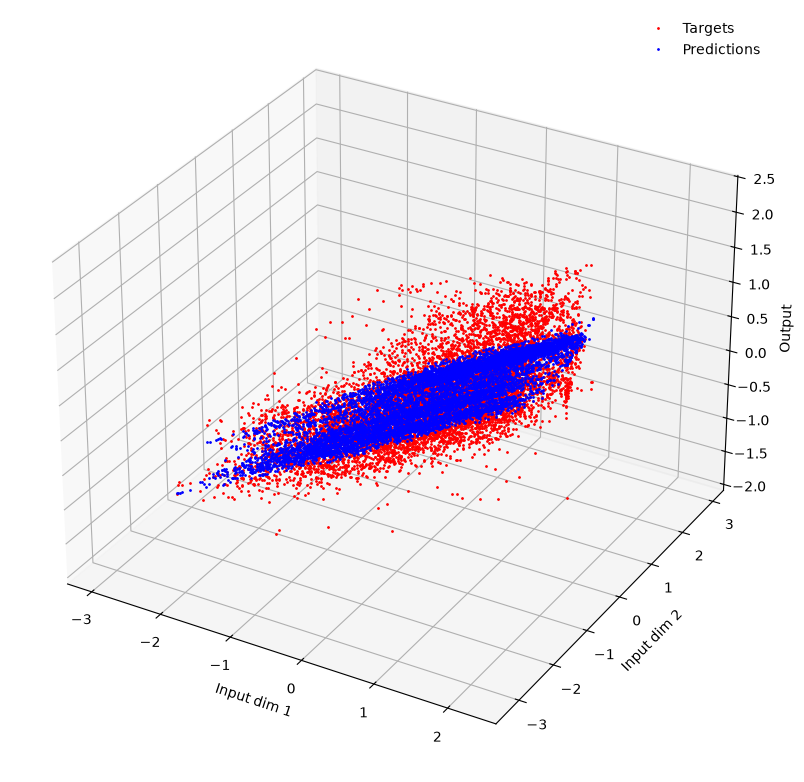

In [27]:
# Plot target and predicted outputs against inputs on same axis
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(inputs[:, 0], inputs[:, 1], targets[:, 0], 'r.', ms=2)
ax.plot(inputs[:, 0], inputs[:, 1], predictions[:, 0], 'b.', ms=2)
ax.set_xlabel('Input dim 1')
ax.set_ylabel('Input dim 2')
ax.set_zlabel('Output')
ax.legend(['Targets', 'Predictions'], frameon=False)
fig.tight_layout()
plt.show()